# **Malaria Detection**

## **Executive Summary**

Malaria remains a significant global health challenge, particularly in regions where access to rapid and reliable diagnostic tools is limited. The disease is caused by parasitic infection transmitted through mosquitoes and can progress rapidly if not identified and treated. Early and accurate diagnosis is critical for improving patient outcomes, reducing transmission, and enabling healthcare providers to deliver timely treatment. However, traditional diagnostic methods, such as manual examination of blood smears under a microscope, can be time-consuming and require highly trained personnel, creating challenges in areas with limited medical resources.

This project addresses the need for more efficient and accessible malaria screening by developing a computer vision model capable of detecting malaria infection in red blood cells. By leveraging deep learning techniques to analyze microscopic cell images, the model aims to assist with automated identification of infected cells and provide a potential tool for supporting medical diagnosis.

The computer vision system is built using a convolutional neural network (CNN). The strategy is to start with a fairly simple model, and add individual elements of complexity and possible improvement in architecture in each step and observe the benefits and tradeoffs of doing so to ascertain whether the inclusion of that added complexity was warranted.

The most effective changes to the model's architecture for improving performance metrics were:
    - changing the activation function to LeakyReLU
    - incorporating 3 convolutional layers
    - utilizing batch normalization to stabilize training
    - manipulating images in the training data using data augmentation

The optimized model yielded performance metrics of:<br>
    * 0.97 validation accuracy<br>
    * 0.11 validation loss<br>
    * 2.69% false positive rate<br>
    * 2.46% false negative rate<br>

The model could be be improved by implementing additional convolutional layers or through trial and error with hyperparameter optimization. While the model does not have adequate performance characteristics for independent diagnosis as a standalone assessment, it can serve as an adjunctive tool to inform clinical judgment and prompt additional investigation.

## <b>Problem and Solution Summary</b>
**The problem:**<br>
Healthcare professionals often require additional information to support timely and informed decision-making, particularly when early indicators of a potential condition may be difficult to identify through existing approaches alone. There is a need for accessible tools that can provide meaningful insights, help identify individuals who may require further evaluation, and support clinical assessment without adding unnecessary burden to existing workflows.<br><br>
**The objectives:**<br>
The objective is to build a computer vision system that can identify red blood cells that are parasitized or uninfected with malaria. The performance metrics will need to be optimized to reduce the risk of false positives or false negatives.<br><br>
**The proposal:**<br>
This image recognition system will be built using a convolutional neural network. CNNs are appropriate because medical images contain spatial patterns and structures that can be learned through convolutional operations, allowing the model to identify relevant features associated with clinical outcomes. If this model is successful, it can serve as a valuable adjunct resource for medical diagnoses and clinical evaluation.<br><br>
**The key questions:**<br>
- Can a CNN learn visual features that distinguish infected cells from healthy cells?<br>
- How accurately can the model classify previously unseen cell images?<br>
- Does the model generalize well to the test dataset, or is it overfitting the training data?<br>
- Which types of errors does the model make most often (false positives vs. false negatives)?<br>



## Recommendations for Implementation

### 1. Define the Intended Use of the Model

The model should be implemented as a **clinical decision-support tool** that provides additional information to assist healthcare professionals in their assessment and decision-making processes. Model predictions should be considered alongside existing clinical information, including patient history, examination findings, and other diagnostic assessments.

The model may provide value by identifying individuals who may benefit from further evaluation, prioritizing cases for review, and supporting more informed clinical decisions.

### 2. Establish Appropriate Clinical Workflows

Successful implementation requires integration of the model into existing healthcare workflows in a manner that complements current practices. Model outputs should be presented in an interpretable and actionable format, such as risk estimates or indicators of cases requiring additional attention.

Clear procedures should be established to define how healthcare professionals review, interpret, and incorporate model predictions into their clinical assessments.

### 3. Provide Training and Guidance for Users

Healthcare professionals using the model should receive appropriate training on its intended purpose, interpretation of outputs, and appropriate use within clinical practice. Guidance should emphasize that the model is designed to support, rather than replace, professional clinical judgment.

Users should understand the circumstances in which additional investigation or diagnostic evaluation may be appropriate based on model predictions and other available clinical evidence.

### 4. Monitor Performance and Clinical Impact

Following implementation, the model should be continuously evaluated to assess its performance, reliability, and effectiveness in real-world clinical settings. Monitoring should consider whether the model improves identification of patients requiring further assessment, supports timely decision-making, and integrates effectively into existing workflows.

Periodic evaluation should also be conducted to ensure that model performance remains consistent across different patient populations and healthcare environments.

## <b>Data Description </b>

There are a total of 24,958 train and 2,600 test images (colored) that we have taken from microscopic images. These images are of the following categories:<br>


**Parasitized:** The parasitized cells contain the Plasmodium parasite which causes malaria<br>
**Uninfected:** The uninfected cells are free of the Plasmodium parasites<br>

### <b>Loading libraries</b>

In [13]:
import numpy as np
import pandas as pd

import os
import glob

import cv2

import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import image_dataset_from_directory

from tensorflow.keras.preprocessing.image import ImageDataGenerator

### <b>Let us load the data</b>

**Note:**
- You must download the dataset from the link provided on Olympus and upload the same to your Google Drive. Then unzip the folder.

In [20]:
train_raw = tf.keras.utils.image_dataset_from_directory(
    "cell_images/cell_images/train",
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary"
)

test_raw = tf.keras.utils.image_dataset_from_directory(
    "cell_images/cell_images/test",
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary"
)

print(train_raw.class_names)

Found 24958 files belonging to 2 classes.
Found 2600 files belonging to 2 classes.
['parasitized', 'uninfected']


The extracted folder has different folders for train and test data will contain the different sizes of images for parasitized and uninfected cells within the respective folder name.

The size of all images must be the same and should be converted to 4D arrays so that they can be used as an input for the convolutional neural network. Also, we need to create the labels for both types of images to be able to train and test the model.

Let's do the same for the training data first and then we will use the same code for the test data as well.

In [25]:
#normalizing pixel values
normalization = tf.keras.layers.Rescaling(1./255)

train_ds = train_raw.map(lambda x, y: (normalization(x), y))
test_ds = test_raw.map(lambda x, y: (normalization(x), y))

train_ds = train_ds.cache().shuffle(1000, reshuffle_each_iteration=True).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

### <b> Check the shape of train and test images

In [24]:
print("Train image batch shape:", train_ds.element_spec[0].shape)
print("Test image batch shape:", test_ds.element_spec[0].shape)

print("Approx train image count:", tf.data.experimental.cardinality(train_ds).numpy() * 32)
print("Approx test image count:", tf.data.experimental.cardinality(test_ds).numpy() * 32)

Train image batch shape: (None, 128, 128, 3)
Test image batch shape: (None, 128, 128, 3)
Approx train image count: 24960
Approx test image count: 2624


### <b> Check the shape of train and test labels

In [25]:
print("Train label batch shape:", train_ds.element_spec[1].shape)
print("Test label batch shape:", test_ds.element_spec[1].shape)

print("Approx train label count:", tf.data.experimental.cardinality(train_ds).numpy() * 32)
print("Approx test label count:", tf.data.experimental.cardinality(test_ds).numpy() * 32)

Train label batch shape: (None, 1)
Test label batch shape: (None, 1)
Approx train label count: 24960
Approx test label count: 2624


#### <b> Observations and insights:</b><br>
There are approximately 24,960 images in the training split and 2624 images in the test split. These come in 3 color channels (RGB) and have been resized to have dimensions of 128x128 pixels. Each image has 1 scalar label.

### <b>Check the minimum and maximum range of pixel values for train and test images

In [26]:
train_min = tf.reduce_min([tf.reduce_min(x) for x, y in train_ds]).numpy()
train_max = tf.reduce_max([tf.reduce_max(x) for x, y in train_ds]).numpy()

print("Train pixel min:", train_min)
print("Train pixel max:", train_max)

test_min = tf.reduce_min([tf.reduce_min(x) for x, y in test_ds]).numpy()
test_max = tf.reduce_max([tf.reduce_max(x) for x, y in test_ds]).numpy()

print("Test pixel min:", test_min)
print("Test pixel max:", test_max)


Train pixel min: 0.0
Train pixel max: 1.0
Test pixel min: 0.0
Test pixel max: 1.0


#### <b> Observations and insights:</b><br>
After applying normalization of 1/255 to pixel values, we see the expected range of 0-1 for the normalized values.



### <b> Count the number of values in both uninfected and parasitized

In [26]:
print("Class names:", class_names)

all_labels = np.concatenate([y.numpy() for x, y in train_ds])

for i, name in enumerate(class_names):
    print(f"{name}: {np.sum(all_labels == i)}")

all_labels_test = np.concatenate([y.numpy() for x, y in test_ds])

for i, name in enumerate(class_names):
    print(f"{name}: {np.sum(all_labels_test == i)}")

Class names: ['parasitized', 'uninfected']
parasitized: 12582
uninfected: 12376
parasitized: 1300
uninfected: 1300


### <b>Normalize the images

In [101]:
#images have already been normalized in the TensorFlow data pipeline

#### <b> Observations and insights: </b><br>
The training and test images are split in approximately a 50/50 ratio between parasitized and uninfected cells.

### <b> Plot to check if the data is balanced

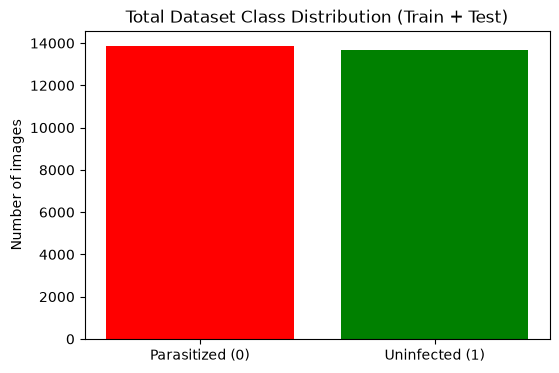

In [28]:
all_labels = np.concatenate([
    y.numpy().reshape(-1) for x, y in train_ds
]).astype(int)

all_labels = np.concatenate([
    all_labels,
    np.concatenate([y.numpy().reshape(-1) for x, y in test_ds]).astype(int)
])

counts = np.bincount(all_labels)

plt.figure(figsize=(6,4))
plt.bar(["Parasitized (0)", "Uninfected (1)"], counts, color=["red", "green"])
plt.title("Total Dataset Class Distribution (Train + Test)")
plt.ylabel("Number of images")
plt.show()

#### <b> Observations and insights: </b><br>
The data is well balanced between parasitized and uninfected cells. Therefore, class imbalance is not expected to bias the model.

### <b>Data Exploration</b>
Let's visualize the images from the train data

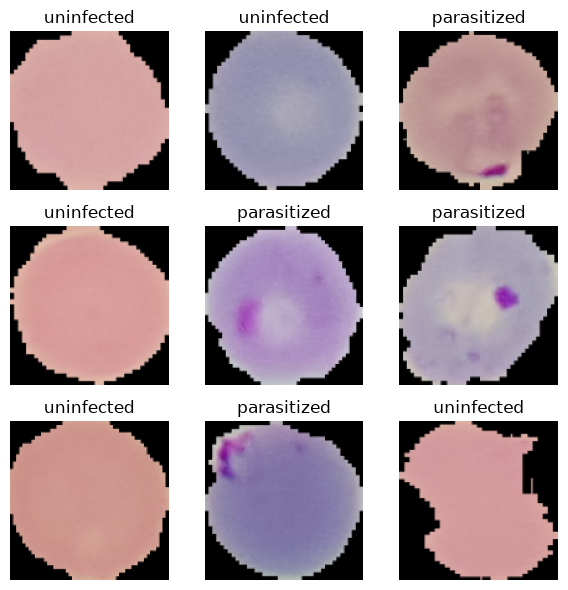

In [29]:
class_names = ["parasitized", "uninfected"]

for images, labels in train_ds.take(1):
    plt.figure(figsize=(6, 6))
    
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        
        plt.imshow(images[i])
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

#### <b> Observations and insights: </b><br>
There is clear visual variation, and meaningful patterns for the model to learn from. The visible structural differences between infected and uninfected cells suggest that a convolutional neural network should be able to learn discriminative spatial features effectively.

### <b> Visualize the images with subplot(6, 6) and figsize = (12, 12)

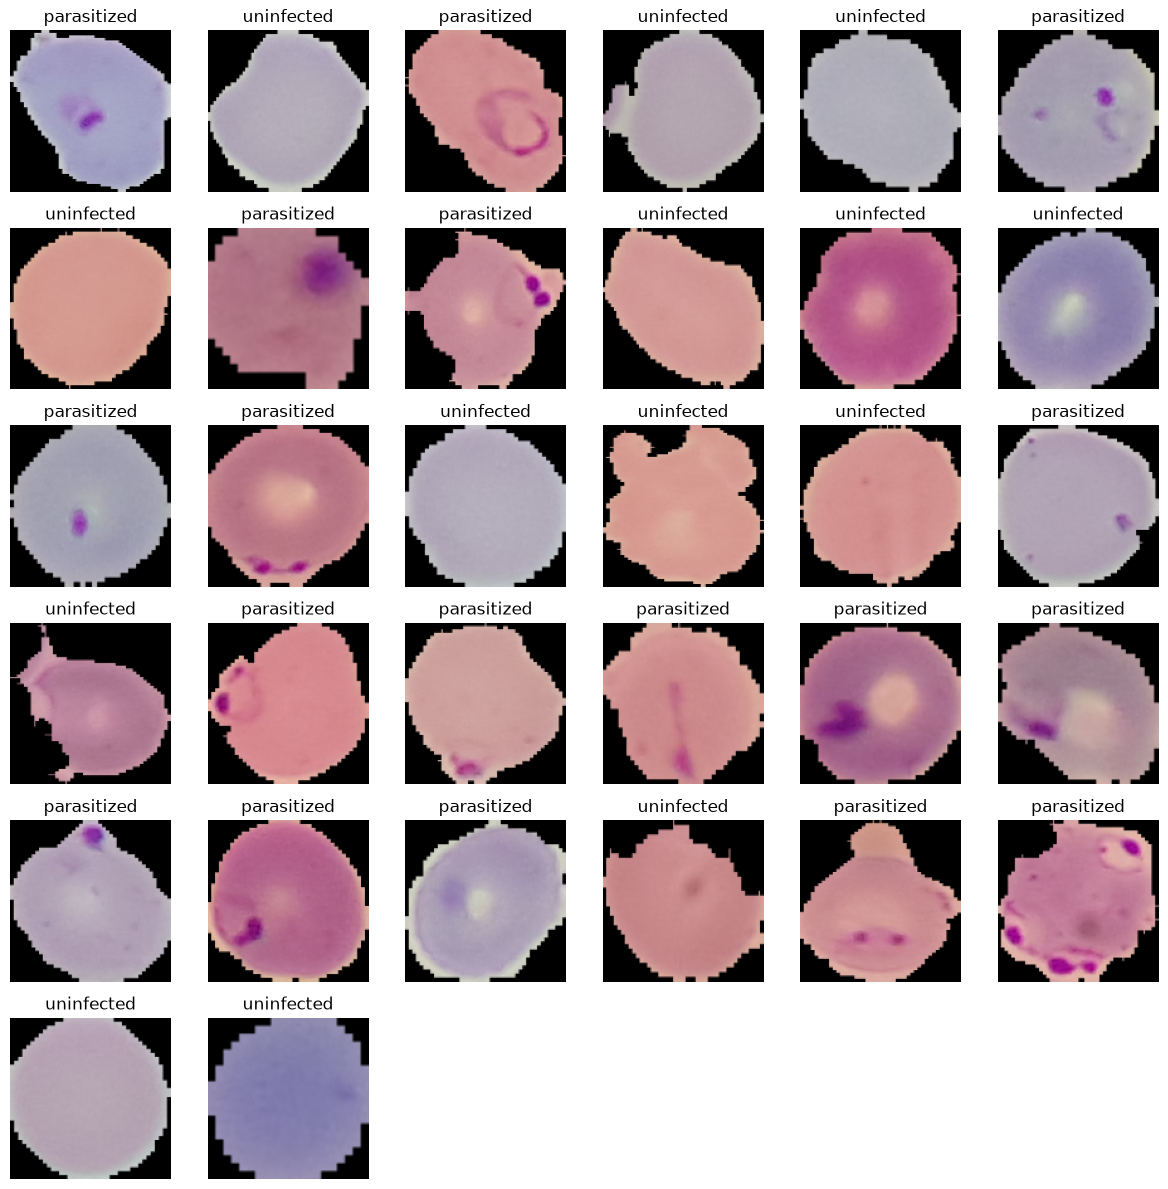

In [30]:
class_names = ["parasitized", "uninfected"]

for images, labels in train_ds.take(1):
    plt.figure(figsize=(12, 12))
    
    # FIX: prevent out-of-bounds error
    n = min(36, images.shape[0])

    for i in range(n):
        ax = plt.subplot(6, 6, i + 1)
        
        plt.imshow(images[i])
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

#### <b>Observations and insights:</b><br>
There is strong visual variance within both uninfected and parasitized cells, however the patterns and color information appear to be relatively simple in nature and robust inputs for the model. Only 32 out of 36 positions on the plot are accounted for due to the batch size of 32.

### <b> Plotting the mean images for parasitized and uninfected

In [105]:

sum_images = {
    class_names[0]: np.zeros((128, 128, 3), dtype=np.float64),
    class_names[1]: np.zeros((128, 128, 3), dtype=np.float64),
}

count_images = {
    class_names[0]: 0,
    class_names[1]: 0,
}

# iterating through dataset
for images, labels in train_ds:
    images = images.numpy()
    labels = labels.numpy().flatten()

    for img, label in zip(images, labels):
        class_name = class_names[int(label)]
        sum_images[class_name] += img
        count_images[class_name] += 1

# computing means
mean_parasitized = sum_images[class_names[0]] / count_images[class_names[0]]
mean_uninfected = sum_images[class_names[1]] / count_images[class_names[1]]

<b> Mean image for parasitized

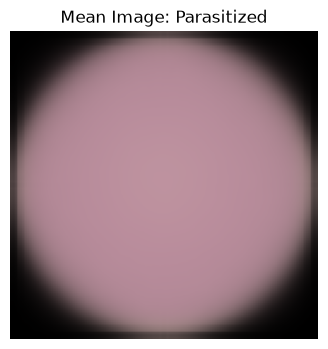

In [106]:
plt.figure(figsize=(4, 4))

plt.imshow(mean_parasitized)
plt.title("Mean Image: Parasitized")
plt.axis("off")

plt.show()

<b> Mean image for uninfected

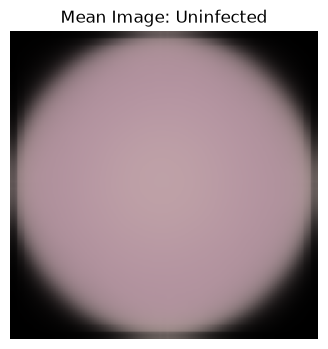

In [107]:
plt.figure(figsize=(4, 4))

plt.imshow(mean_uninfected)
plt.title("Mean Image: Uninfected")
plt.axis("off")

plt.show()


#### <b> Observations and insights: </b><br>
The biological variance and parasitization signals and patterns apparent in the original images have mostly converged to simple texture and color distribution in the mean images.

### <b>Converting RGB to HSV of Images

### <b> Converting the train data

In [108]:
def rgb_to_hsv(image, label):
    image = tf.image.rgb_to_hsv(image)
    return image, label

train_hsv_ds = train_ds.map(rgb_to_hsv)

### <b> Converting the test data

In [109]:
def rgb_to_hsv(image, label):
    image = tf.image.rgb_to_hsv(image)
    return image, label

test_hsv_ds = test_ds.map(rgb_to_hsv)

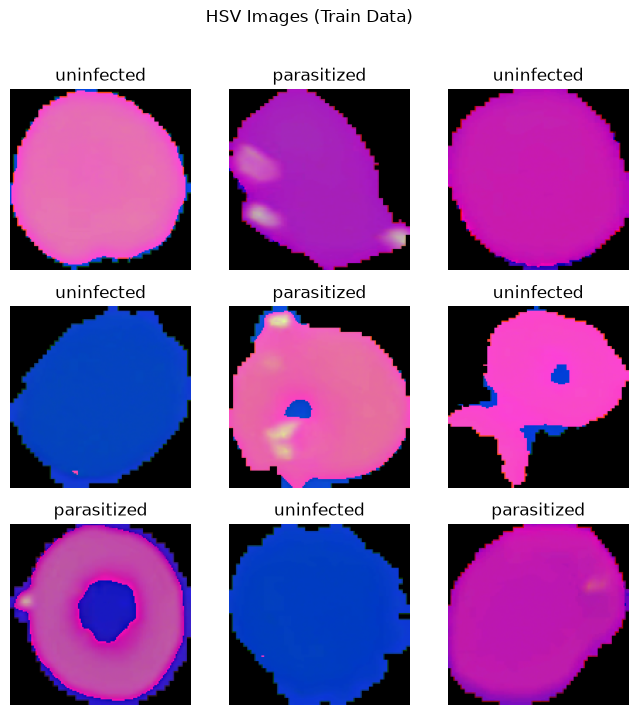

In [110]:
plt.figure(figsize=(8, 8))

for images, labels in train_ds.take(1):
    hsv_images = tf.image.rgb_to_hsv(images)

    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        img = hsv_images[i].numpy()
        label = labels[i].numpy().item()

        plt.imshow(img)
        plt.title(class_names[int(label)])
        plt.axis("off")

plt.suptitle("HSV Images (Train Data)")
plt.show()

#### <b>Observations and insights: </b><br>
HSV conversion leads to a distinctive change in the color scheme of the images. Visual patterns and information are still apparent. The parasitized cells among the cells sampled here appear to contain spots or streaks of brighter (near white) hue, whereas the uninfected cells do not have this.

### <b> Processing Images using Gaussian Blurring

### <b> Gaussian Blurring on train data

In [31]:
def gaussian_blur(image, label):
    image = tf.cast(image, tf.float32)

    # 5x5 Gaussian kernel
    kernel = tf.constant([
        [1, 4, 6, 4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1, 4, 6, 4, 1]
    ], dtype=tf.float32)

    kernel = kernel / 256.0

    kernel = tf.reshape(kernel, (5, 5, 1, 1))
    kernel = tf.tile(kernel, [1, 1, 3, 1])

    image = tf.nn.depthwise_conv2d(
        image,
        kernel,
        strides=[1, 1, 1, 1],
        padding="SAME"
    )

    return image, label


train_blur_ds = train_ds.map(gaussian_blur)

### <b> Gaussian Blurring on test data

In [76]:
test_blur_ds = test_ds.map(gaussian_blur)

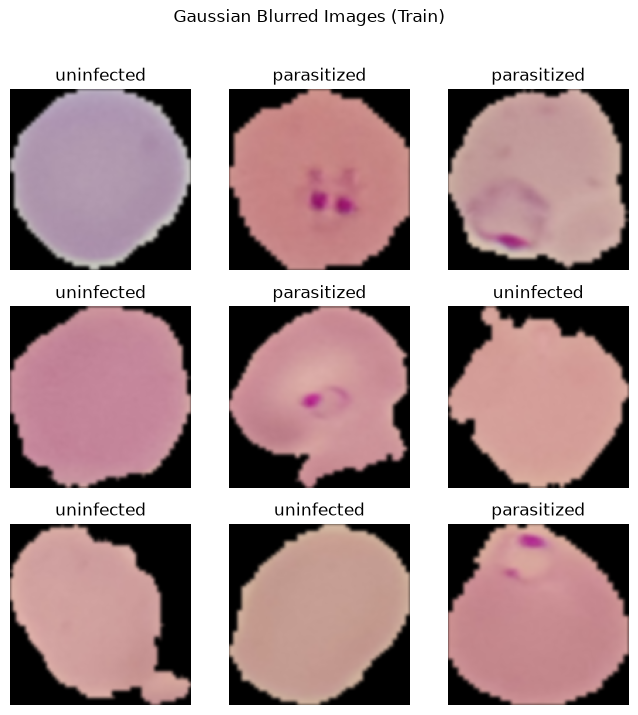

In [112]:
plt.figure(figsize=(8, 8))

for images, labels in train_blur_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i].numpy().item())])
        plt.axis("off")

plt.suptitle("Gaussian Blurred Images (Train)")
plt.show()

#### **Observations and insights:**<br>
Gaussian blur produces minor visible changes at this resolution (128×128). Smoothing of edges and texture is occurring but is somewhat imperceptible at this scale.<br><br>
**Think About It:** <br>
Blurring would likely be a counterproductive step to take because it risks losing the information the model will need to make an accurate determination.<br>
We could also utilize data augmentation to aid in generalizability of the model.

## **Model Building**

### **Base Model**




### <b> Importing the required libraries for building and training our Model

In [149]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout,
    BatchNormalization, Activation,
    LeakyReLU
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix

### <b> Building the model

In [120]:
model = Sequential([
    Input(shape=(128, 128, 3)),

    Conv2D(16, (3,3), activation='relu'),
    MaxPooling2D(),

    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

### <b> Compiling the model

In [121]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

<b> Using Callbacks

In [122]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

<b> Fit and train our Model

In [124]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=8,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9063 - loss: 0.2332
Epoch 1: val_loss improved from 0.24768 to 0.22467, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 33s 42ms/step - accuracy: 0.9063 - loss: 0.2332 - val_accuracy: 0.8950 - val_loss: 0.2247
Epoch 2/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9115 - loss: 0.2112
Epoch 2: val_loss did not improve from 0.22467
780/780 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.9115 - loss: 0.2112 - val_accuracy: 0.8865 - val_loss: 0.2371
Epoch 3/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9233 - loss: 0.1938
Epoch 3: val_loss improved from 0.22467 to 0.20837, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 35s 44ms/step - accuracy: 0.9233 - loss: 0.1938 - val_accuracy: 0.9088 - val_loss: 0.2084
Epoch 4/8
779/780 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 

### <b> Evaluating the model on test data

In [125]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9335 - loss: 0.1715
Test Loss: 0.1715102195739746
Test Accuracy: 0.9334615468978882


<b> Plotting the confusion matrix

In [129]:
test_ds_clean = test_raw.map(lambda x, y: (normalization(x), y))

y_true = []
y_pred = []

for images, labels in test_ds_clean:
    preds = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

y_pred = (y_pred > 0.5).astype(int).reshape(-1)
y_true = y_true.reshape(-1)

print(confusion_matrix(y_true, y_pred))

[[1236   64]
 [ 109 1191]]


<b>Plotting the train and validation curves

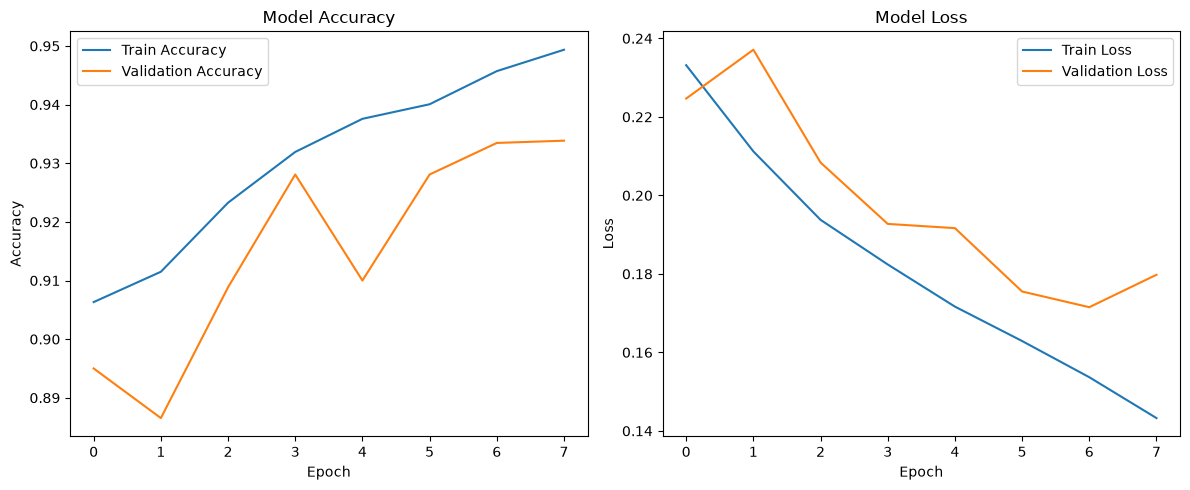

In [130]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

So now let's try to build another model with few more add on layers and try to check if we can try to improve the model. Therefore try to build a model by adding few layers if required and altering the activation functions.

### <b> Model 1
#### <b> Trying to improve the performance of our model by adding new layers


In [135]:
# Model 1 Improvement Strategy

# In this model, we aim to improve performance by:
# 1. Increasing network depth by adding an additional convolutional layer
# 2. Utilizing the ELU activation function rather than ReLU to potentially improve non-linearity learning

# This will ideally help the model learn more complex feature representations
# compared to the baseline CNN.

### <b> Building the Model

In [141]:
model1 = Sequential([
    
    Input(shape=(128, 128, 3)),

    Conv2D(16, (3,3)),
    Activation('elu'),
    MaxPooling2D(),

    Conv2D(32, (3,3)),
    Activation('elu'),
    MaxPooling2D(),

    # NEW LAYER
    Conv2D(64, (3,3)),
    Activation('elu'),
    MaxPooling2D(),

    Flatten(),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

### <b> Compiling the model

In [142]:
model1.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

<b> Using Callbacks

In [143]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint1 = ModelCheckpoint(
    "model1_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

<b>Fit and Train the model

In [145]:
history1 = model1.fit(
    train_ds,
    validation_data=test_ds,
    epochs=8,
    callbacks=[early_stop, checkpoint1]
)

Epoch 1/8
779/780 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9240 - loss: 0.2025
Epoch 1: val_loss improved from 0.24714 to 0.21402, saving model to model1_best.keras

Epoch 1: finished saving model to model1_best.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - accuracy: 0.9240 - loss: 0.2024 - val_accuracy: 0.9215 - val_loss: 0.2140
Epoch 2/8
779/780 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9324 - loss: 0.1842
Epoch 2: val_loss improved from 0.21402 to 0.17232, saving model to model1_best.keras

Epoch 2: finished saving model to model1_best.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - accuracy: 0.9324 - loss: 0.1842 - val_accuracy: 0.9369 - val_loss: 0.1723
Epoch 3/8
779/780 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9404 - loss: 0.1618
Epoch 3: val_loss improved from 0.17232 to 0.16454, saving model to model1_best.keras

Epoch 3: finished saving model to model1_best.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - accuracy: 0.9404 - loss: 0.1617 - val_accu

### <b> Evaluating the model

In [146]:
test_loss, test_accuracy = model1.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9565 - loss: 0.1194
Test Loss: 0.11942137777805328
Test Accuracy: 0.9565384387969971


<b> Plotting the confusion matrix

In [147]:
test_ds_clean = test_raw.map(lambda x, y: (normalization(x), y))

y_true = []
y_pred = []

for images, labels in test_ds_clean:
    preds = model1.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

y_pred = (y_pred > 0.5).astype(int).reshape(-1)
y_true = y_true.reshape(-1)

print(confusion_matrix(y_true, y_pred))

[[1240   60]
 [  53 1247]]


<b> Plotting the train and the validation curves

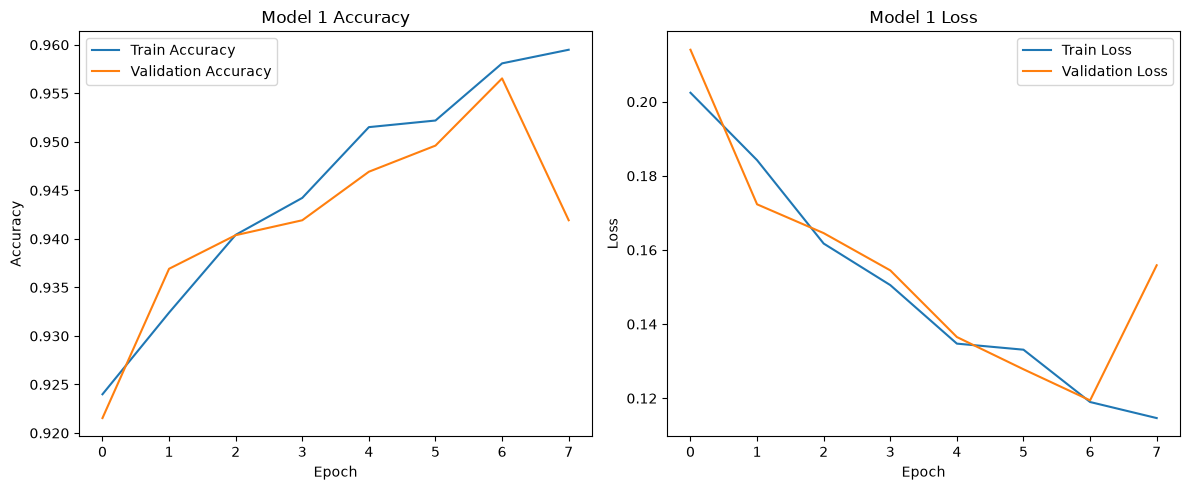

In [148]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history1.history['accuracy'], label='Train Accuracy')
plt.plot(history1.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model 1 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history1.history['loss'], label='Train Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.title('Model 1 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

The best performing iteration of the model with the modifications to layer depth and activation function yielded a significant improvement, going from a test loss of 0.172 to a test loss of 0.119.

### <b>Think about it:</b><br>
Now let's build a model with LeakyRelu as the activation function  

*  Can the model performance be improved if we change our activation function to LeakyRelu?
*  Can BatchNormalization improve our model?

Let us try to build a model using BatchNormalization and using LeakyRelu as our activation function.

### <b> Model 2 with Batch Normalization

In [ ]:
# Model 2: Batch Normalization + LeakyReLU Improvements

# This model builds upon the improved CNN architecture from Model 1,
# which already introduced ELU activation and an additional convolutional layer.

# In this model, we further enhance performance by introducing Batch Normalization
# after convolutional and dense layers to stabilize training, reduce internal
# covariate shift, and improve convergence speed.

# We also introduce LeakyReLU activation in place of ELU/ReLU within hidden layers
# to improve gradient flow for negative inputs and reduce the risk of inactive neurons.

# The objective of this model is to improve training stability, convergence behavior,
# and generalization performance.

### <b> Building the Model

In [155]:
model2 = Sequential([

    Input(shape=(128, 128, 3)),

    Conv2D(16, (3,3), padding='same'),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D(),

    Conv2D(32, (3,3), padding='same'),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D(),

    # Block 3 (from Model 1 improvement retained)
    Conv2D(64, (3,3), padding='same'),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D(),

    Flatten(),

    Dense(64),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),

    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

### <b>Compiling the model

In [156]:
model2.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

<b> Using callbacks

In [157]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint2 = ModelCheckpoint(
    "model2_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

<b>Fit and train the model

In [159]:
history2 = model2.fit(
    train_ds,
    validation_data=test_ds,
    epochs=8,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9706 - loss: 0.0909
Epoch 1: val_loss improved from 0.15984 to 0.09808, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 110s 141ms/step - accuracy: 0.9706 - loss: 0.0909 - val_accuracy: 0.9662 - val_loss: 0.0981
Epoch 2/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.9756 - loss: 0.0769
Epoch 2: val_loss did not improve from 0.09808
780/780 ━━━━━━━━━━━━━━━━━━━━ 110s 140ms/step - accuracy: 0.9756 - loss: 0.0769 - val_accuracy: 0.9677 - val_loss: 0.1152
Epoch 3/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.9800 - loss: 0.0656
Epoch 3: val_loss improved from 0.09808 to 0.09430, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 111s 142ms/step - accuracy: 0.9800 - loss: 0.0656 - val_accuracy: 0.9704 - val_loss: 0.0943
Epoch 4/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - 

<b>Plotting the train and validation accuracy

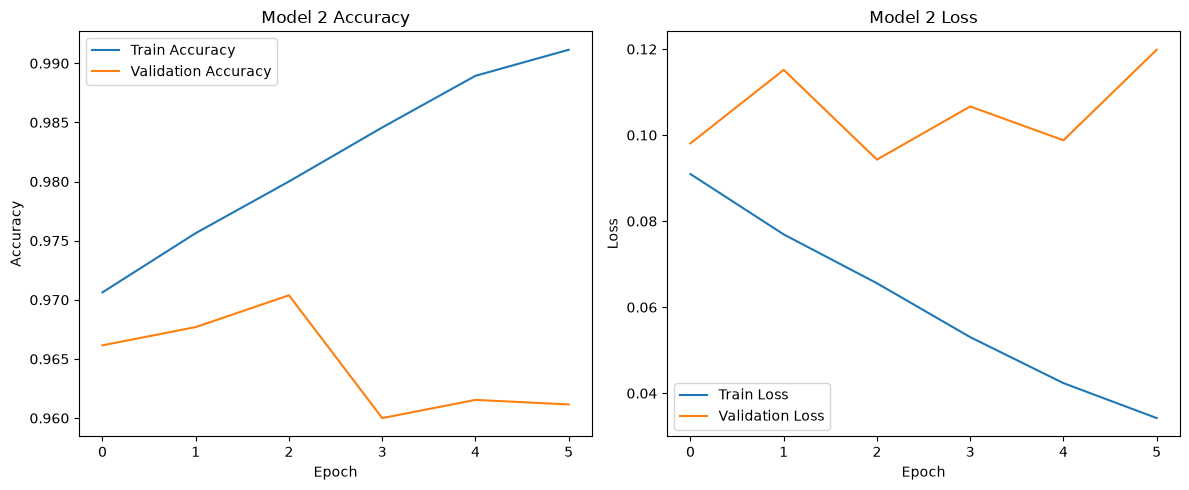

In [160]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history2.history['accuracy'], label='Train Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model 2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history2.history['loss'], label='Train Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.title('Model 2 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


### <b>Evaluating the model

In [161]:
test_loss, test_accuracy = model2.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9704 - loss: 0.0943
Test Loss: 0.09430190175771713
Test Accuracy: 0.9703845977783203


#### <b>Observations and insights: </b><br>
Adding the batch normalization and using LeakyReLU activation function has yielded another improvement in the model, from a test loss of 0.119 to a test loss of 0.0943. Test accuracy increased from 0.957 to 0.970.

<b> Generate the classification report and confusion matrix

In [163]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model2.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true).reshape(-1)
y_pred = (np.array(y_pred) > 0.5).astype(int).reshape(-1)

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Confusion Matrix:
[[1268   32]
 [  45 1255]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.97      0.98      0.97      1300
         1.0       0.98      0.97      0.97      1300

    accuracy                           0.97      2600
   macro avg       0.97      0.97      0.97      2600
weighted avg       0.97      0.97      0.97      2600



###**Think About It :**<br>

* Can we improve the model with Image Data Augmentation?<br><br>

Yes, image data augmentation can potentially improve the model's performance and generalization. Data augmentation artificially increases the diversity of the training dataset by creating modified versions of existing images. This helps reduce overfitting and enables the model to learn features that are robust to variations in the input images. We will have to implement it and compare the results to be certain though.

* References to image data augmentation can be seen below:
  *   [Image Augmentation for Computer Vision](https://www.mygreatlearning.com/blog/understanding-data-augmentation/)
  *   [How to Configure Image Data Augmentation in Keras?](https://machinelearningmastery.com/how-to-configure-image-data-augmentation-when-training-deep-learning-neural-networks/)





### <b>Model 3 with Data Augmentation

In [ ]:
# Model 3: Image Data Augmentation

# This model builds upon Model 2 by introducing image data augmentation
# during training. Data augmentation generates modified versions of the
# training images to increase data diversity and reduce overfitting.

# The augmentation techniques include small random rotations, zooming,
# translations, and horizontal flips. These transformations help the
# model become more robust to variations in cell orientation and position
# while preserving the important visual characteristics needed for
# malaria cell classification.

# The objective is to improve the model's generalization performance on
# unseen test images without changing the underlying dataset.

### <b> Use image data generator

In [164]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode='nearest'
)

# No augmentation for validation/test data
test_datagen = ImageDataGenerator()

#### <B>Visualizing Augmented images

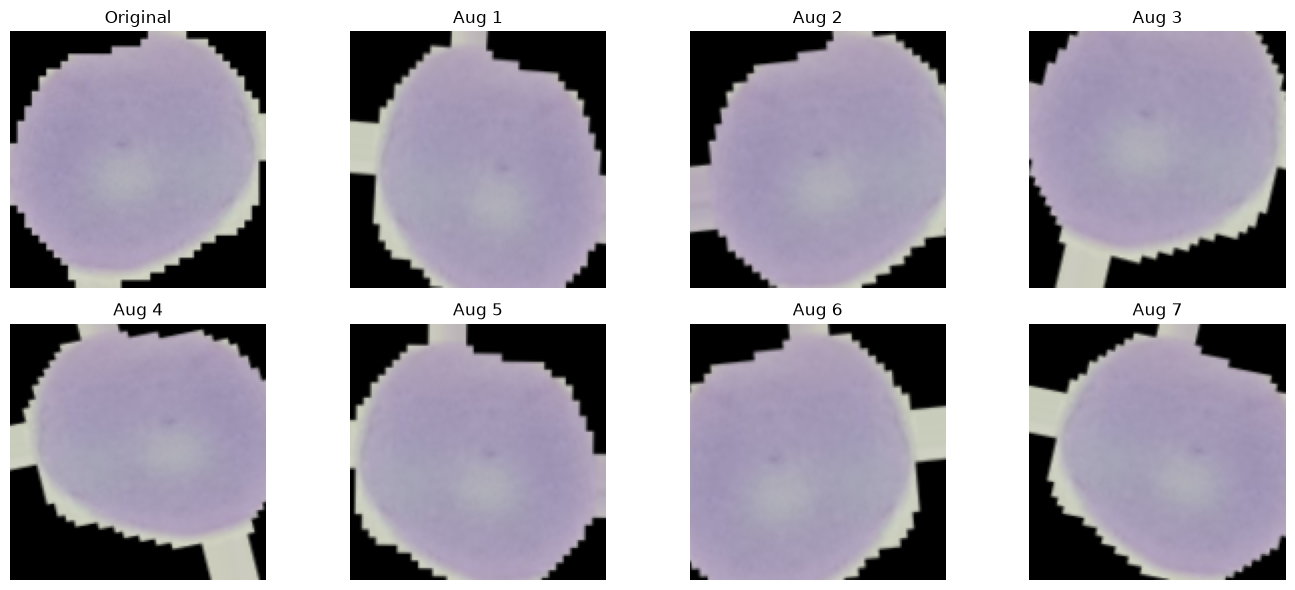

In [166]:
images, labels = next(iter(train_ds))
image = images[0].numpy()

plt.figure(figsize=(14, 6))

# Original image
plt.subplot(2, 4, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

# Augmented images
for i in range(7):
    augmented = train_datagen.random_transform(image)

    plt.subplot(2, 4, i + 2)
    plt.imshow(np.clip(augmented, 0, 1))
    plt.title(f"Aug {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

#### <b>Observations and insights:</b>
We can visually confirm the variations being created in contrast with the original image, as seen in the plot above. Rotations, changes in scale, and reflections/translations are all being introduced to make the training dataset more robust as an input to train the model.

### <b>Building the Model

In [5]:
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    LeakyReLU,
    RandomRotation,
    RandomZoom,
    RandomTranslation,
    RandomFlip
)

model3 = Sequential([

    Input(shape=(128, 128, 3)),

    # Data Augmentation
    RandomFlip("horizontal"),
    RandomRotation(0.10),
    RandomZoom(0.10),
    RandomTranslation(0.10, 0.10),

    # CNN
    Conv2D(16, (3,3), padding="same"),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D(),

    Conv2D(32, (3,3), padding="same"),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D(),

    Conv2D(64, (3,3), padding="same"),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),
    MaxPooling2D(),

    Flatten(),

    Dense(64),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

In [176]:
model3.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

<b>Using Callbacks

In [177]:
early_stop3 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint3 = ModelCheckpoint(
    "model3_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

<b> Fit and Train the model

In [179]:
history3 = model3.fit(
    train_ds,
    validation_data=test_ds,
    epochs=8,
    callbacks=[early_stop3, checkpoint3]
)

Epoch 1/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.9387 - loss: 0.1760
Epoch 1: val_loss improved from 0.71209 to 0.36050, saving model to model3_best.keras

Epoch 1: finished saving model to model3_best.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 126s 162ms/step - accuracy: 0.9387 - loss: 0.1760 - val_accuracy: 0.8419 - val_loss: 0.3605
Epoch 2/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.9447 - loss: 0.1574
Epoch 2: val_loss improved from 0.36050 to 0.16536, saving model to model3_best.keras

Epoch 2: finished saving model to model3_best.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 126s 161ms/step - accuracy: 0.9447 - loss: 0.1574 - val_accuracy: 0.9488 - val_loss: 0.1654
Epoch 3/8
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9493 - loss: 0.1438
Epoch 3: val_loss improved from 0.16536 to 0.15191, saving model to model3_best.keras

Epoch 3: finished saving model to model3_best.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 125s 160ms/step - accuracy: 0.9493 - loss: 0.1438 -

### <B>Evaluating the model

<b>Plot the train and validation accuracy

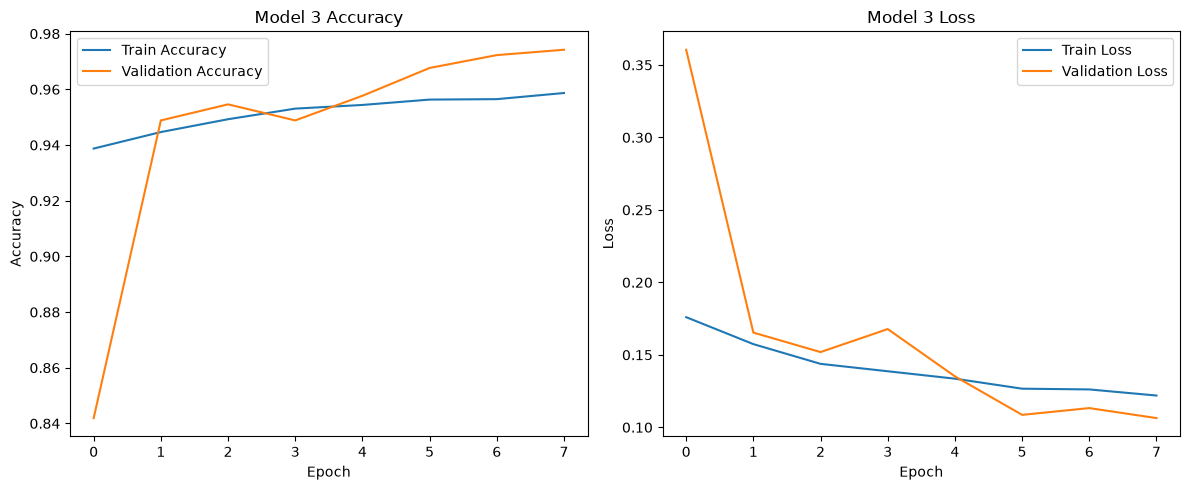

In [180]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history3.history['accuracy'], label='Train Accuracy')
plt.plot(history3.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model 3 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history3.history['loss'], label='Train Loss')
plt.plot(history3.history['val_loss'], label='Validation Loss')
plt.title('Model 3 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


<B>Plotting the classification report and confusion matrix

In [40]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model3.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true).reshape(-1)
y_pred = (np.array(y_pred) > 0.5).astype(int).reshape(-1)

cm = confusion_matrix(y_true, y_pred)

# Reorder rows and columns:
# Original order: [parasitized (0), uninfected (1)]
# New order:      [uninfected (1), parasitized (0)]

cm_clinical = cm[np.ix_([1, 0], [1, 0])]

print("Confusion Matrix:")
print(cm_clinical)
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[1, 0],
    target_names=["Uninfected", "Parasitized"]
))

Confusion Matrix:
[[1265   35]
 [  32 1268]]

Classification Report:
              precision    recall  f1-score   support

  Uninfected       0.98      0.97      0.97      1300
 Parasitized       0.97      0.98      0.97      1300

    accuracy                           0.97      2600
   macro avg       0.97      0.97      0.97      2600
weighted avg       0.97      0.97      0.97      2600



The model has slightly improved after implementing the data augmentation. The validation accuracy increased from 0.961 to 0.974. The validation loss also decreased. Because of this, we will move forward with model3 as our best version so far.

<b> Now, let us try to use a pretrained model like VGG16 and check how it performs on our data.

### **Pre-trained model (VGG16)**
- Import VGG16 network upto any layer you choose
- Add Fully Connected Layers on top of it

In [6]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import preprocess_input

train_ds = train_raw.map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y))
test_ds = test_raw.map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y))

train_ds = train_ds.cache().shuffle(1000, reshuffle_each_iteration=True).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze convolutional base
base_model.trainable = False

vgg_model = Sequential([
    base_model,

    GlobalAveragePooling2D(),

    Dense(128),
    BatchNormalization(),
    LeakyReLU(negative_slope=0.1),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

### <b>Compiling the model

In [9]:
vgg_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

<b> Using Callbacks

In [10]:
early_stop_cb = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)


checkpoint_cb = ModelCheckpoint(
    filepath="vgg16_best_model.keras",
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

<b>Fit and Train the model

In [12]:
history_vgg = vgg_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5,
    shuffle=False,
    callbacks=[early_stop_cb, checkpoint_cb]
)

Epoch 1/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 666ms/step - accuracy: 0.9350 - loss: 0.1755
Epoch 1: val_loss improved from None to 0.13959, saving model to vgg16_best_model.keras

Epoch 1: finished saving model to vgg16_best_model.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 576s 738ms/step - accuracy: 0.9350 - loss: 0.1755 - val_accuracy: 0.9454 - val_loss: 0.1396
Epoch 2/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 661ms/step - accuracy: 0.9483 - loss: 0.1401
Epoch 2: val_loss improved from 0.13959 to 0.12489, saving model to vgg16_best_model.keras

Epoch 2: finished saving model to vgg16_best_model.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 569s 730ms/step - accuracy: 0.9483 - loss: 0.1401 - val_accuracy: 0.9531 - val_loss: 0.1249
Epoch 3/5
780/780 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - accuracy: 0.9547 - loss: 0.1263
Epoch 3: val_loss improved from 0.12489 to 0.11622, saving model to vgg16_best_model.keras

Epoch 3: finished saving model to vgg16_best_model.keras
780/780 ━━━━━━━━━━━━━━━━━━━━ 559s 717ms/step - accura

<b>Plot the train and validation accuracy

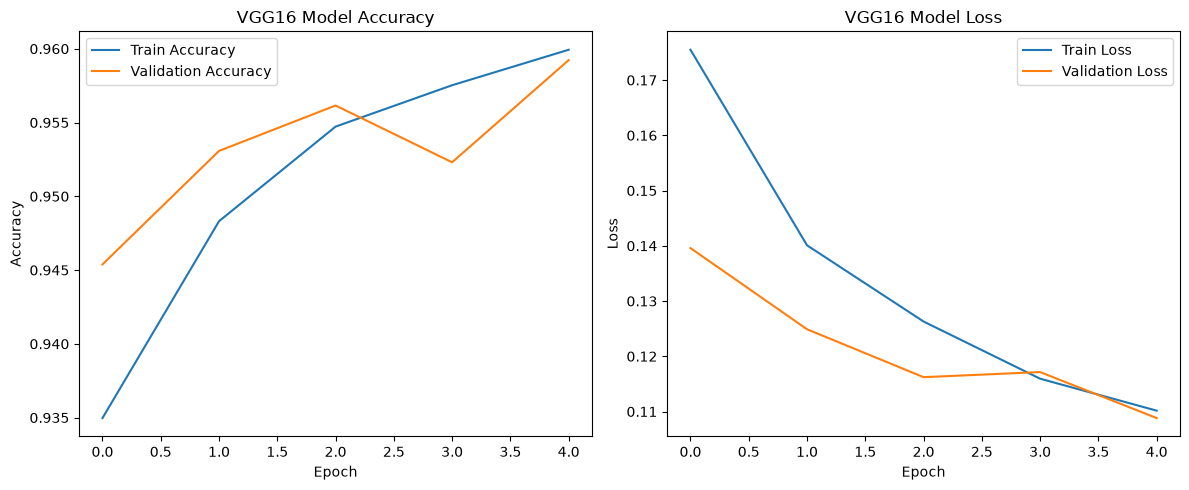

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_vgg.history['accuracy'], label='Train Accuracy')
plt.plot(history_vgg.history['val_accuracy'], label='Validation Accuracy')
plt.title('VGG16 Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_vgg.history['loss'], label='Train Loss')
plt.plot(history_vgg.history['val_loss'], label='Validation Loss')
plt.title('VGG16 Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### <b>Observations and insights:</b> 

*   The VGG16 pre-trained model is performing slightly worse than model 3 but still shows good accuracy and improvement with training. It doesn't show signs of overfitting since the train and validation metrics are both improving with additional training.

### <b> Evaluating the model

<b>Plotting the classification report and confusion matrix

In [16]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = vgg_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true).reshape(-1)
y_pred = (np.array(y_pred) > 0.5).astype(int).reshape(-1)

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Confusion Matrix:
[[1250   50]
 [  56 1244]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      0.96      0.96      1300
         1.0       0.96      0.96      0.96      1300

    accuracy                           0.96      2600
   macro avg       0.96      0.96      0.96      2600
weighted avg       0.96      0.96      0.96      2600



### <b>Choosing a final model:</b>
*  The false positive and false negative rates for the pre-trained model are similarly low, roughly 2% for each.
*  Since model 3 has lower false negative/positive rates, superior trainining and validation metrics, and more consistency across training epochs, model 3 will be the final model.


#### <b> Observations and Conclusions drawn from the final model: 



**Improvements that can be done:**<br>


*  There is the potential to optimize the model's performance further with the ideal amount of training, however to avoid the risk of overfitting I limited the training after the model performance stabilized to ensure that the model will perform well on images it hasn't seen.

*  The model performance could potentially be improved with variations in the architecture of the CNN, but this comes at a heavy computational cost given that the complexity would need to increase further.

### **Insights**

#### **Refined insights**:

The data is robust with structural patterns and variation for the model to learn and apply. In addition, the cell images have variations in orientation, shape, and size that make strategies like data augmentation highly applicable.

#### **Comparison of various techniques and their relative performance**:

The largest improvement came from implementing batch normalization and utilizing the LeakyReLU activation function. The model that includes these as well as data augmentation is performing the best of the models tested. The performance of the model could be improved through potential modifications to hyperparameters, learning rates, and other tunable features of the model.

#### **Proposal for the final solution design**:

The proposed model is model3, which includes 3 convolutional layers, batch normalization, LeakyReLU activation function, and data augmentation. In testing different structures for the CNN, this combination yielded the strongest performance on the validation data of 0.974 validation accuracy and 0.106 validation loss.